# Problema de inventario.

## Descripción del Problema.

Considere un producto en una tienda. Debemos construir una estrategia para maximizar las ganancias.

## Descripción del Modelo.

Para construir nuestro modelo. Vamos a definir las variables elementales.

* $x_t$ es la cantidad del producto disponible en la etapa $t$.
* $\xi_t$ es la cantidad de producto solicitada en la etapa $t$.
* $a_t$ es la cantidad de prodcuto solicitada en la etapa $t$.

Notemos que dada la cantidad inicial $x_0$ en la etapa cero. En la siguiente etapa, despues de solicitar $a_1$ productos, habremos necesitado $\xi_1$ productos. Entonces la cantidad de producto en la siguiente etapa sería 
$$
    x_1 = x_0 + a_0 - \xi_1.
$$
Sin embargo, puede darse el caso que $\xi_1>x_0+a_0$, entonces nos quedaremos con la parte positiva. En general, la cantidad de producto en la etapa $t + 1$ esta dado por 
$$
    x_{t+1} = (x_t + a_t - \xi_{t+1})^{+},(\cdot)^{+}=\max(\cdot, 0)
$$

In [81]:
import numpy as np
from neuralnetworks.nn import sigmoid

def state(x, a, e):
    y = np.max([x + a - e, 0])
    return y

### Función de Recompensa

A lo largo de la libreta iremos revisando diferentes funciones de ganancia en función de los aditamientos que vayamos definiendo.

#### Ganancia simplificada.

La ganancia simplificada consiste en calcular ganancia comparando la ganancia bruta menos los costos. Sea $V$ el precio de venta y $C$ el costo de solicitar el producto, entonces 

$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t, R_0 = 0
$$

In [82]:
def simple_reward(x, a, e, v, c):
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    return reward


#### Ganancia sincera.

Definimos la ganancia sincera la ganancia simplificada pero agregando una penalización si la demanda llega a ser mayor al producto disponible. En general, podmeos definirla con una penalización constante $\eta$
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta I_{\xi_{t+1}>x_t+a_t}.
$$

Pero, en caso de conocer la información, puede consideraese proporcional al producto no vendido por carencia
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta \max\{\xi_{t+1}-x_t-a_t, 0\}.
$$


In [83]:
def pure_reward(x,a,e,v,c,eta):
    # No observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = 1 if e > x + a else 0
    return reward - eta * pen

# Miercoles 4 NO CLASE
# Jueves 4 a 6 (Virtual)
# Sabado 7 NO CLASE (Actividad)

def pure_reward_obs(x, a, e, v, c, eta):
    # observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = eta * np.max([e > x + a, 0])
    return reward - pen


### Demanda

Por lo general la demanda es desconocida. Pero para esta libreta estara dada


/tmp/ipykernel_101810/3215332387.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


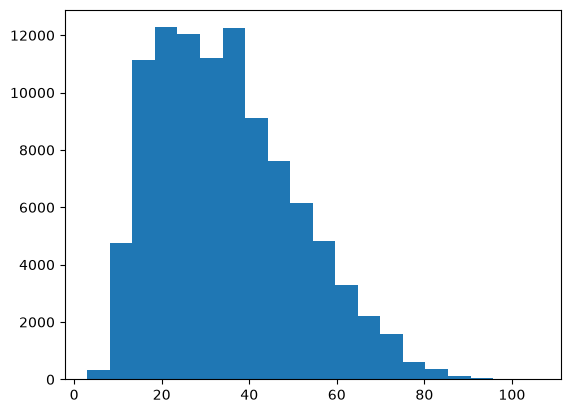

In [84]:
import matplotlib.pyplot as plt

def demmand():
    y = np.random.poisson(lam=10) + np.random.randint(1,10) * np.random.binomial(10, 0.5)
    return y

demmand_sample = [demmand() for _ in range(100_000)]

fig, ax = plt.subplots()
ax.hist(demmand_sample, bins=20)
fig.show()


## Simulaciones.
### Dinamica
Con el modelo terminado procedemos a poner pruebas.

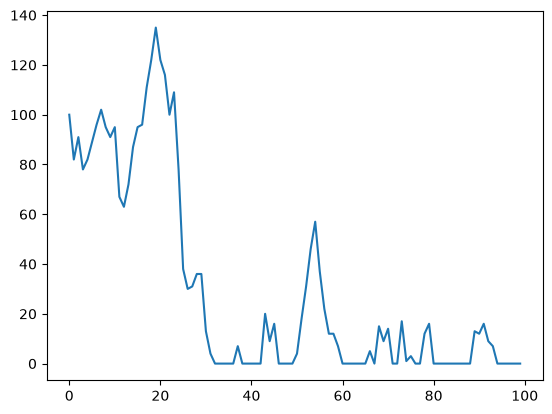

In [85]:
def simulate(x0, actions):
    days = len(actions)
    history = []
    for n in range(days):
        e = demmand()
        xp1 = state(x0, actions[n], e)
        h = (x0, actions[n], e)
        x0 = xp1
        history.append(h)
    return history

test = simulate(100, [30 for _ in range(100)])
test

xt = [u[0] for u in test]
plt.plot(xt)

### Recompensa

Luego, calculamos la recompensa por etapa y la recompensa final.

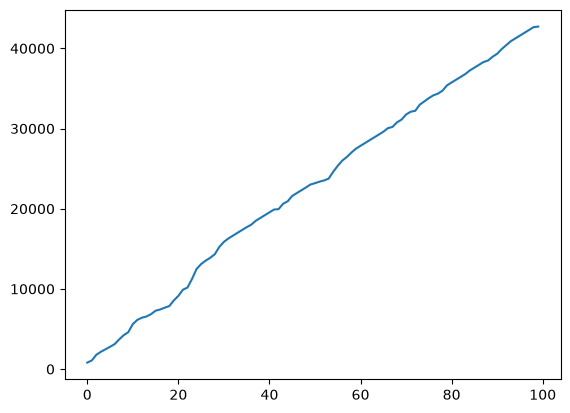

In [86]:
PRECIO_VENTA = 20
COSTO = 5
ETA = 100


item = test[0]
values = []
for item in test:    
    values.append(pure_reward_obs(item[0], item[1], item[2], PRECIO_VENTA, COSTO, ETA))

values = np.array(values)
plt.plot(values.cumsum())

## Uso de Red Neuronal.

Ahora, vamos a construir la red Neuronal que pretende resolver este problema. Notemos que ahora $\mathfrak{m}(\cdot, \Theta):\mathbb{R}^2\to\mathbb{R}$

### Una neurona. 


$$
    \mathfrak{m}(\mathbf{x}, \Theta) = c\sigma\left((w_1,w_2)^{\top}\left[\begin{array}{c}
    x_1 \\ x_2
    \end{array}\right] + b_1\right)
$$

^

In [108]:
NEURONS = 5

x_t, a_t = (100, 20)
v0 = np.array([[x_t], [a_t]])

2 * sigmoid(np.dot(np.array([1, 1]), v0) + 10)
q = np.ones((2, 1))

M = np.random.standard_normal((NEURONS, 1 + len(v0) + 1))
M

array([[-1.53025801, -0.56414232,  1.25115231, -0.45770973],
       [ 0.60658225,  0.56305928,  0.95892574, -1.36137243],
       [-0.33264457,  0.03294695,  0.9200551 ,  0.20856214],
       [ 0.77785349, -1.30716449,  0.01685385,  0.39784927],
       [ 1.05959   ,  0.24190843, -0.36104051,  1.07487622]])

In [110]:
s = M.flatten()
s

array([-1.53025801, -0.56414232,  1.25115231, -0.45770973,  0.60658225,
        0.56305928,  0.95892574, -1.36137243, -0.33264457,  0.03294695,
        0.9200551 ,  0.20856214,  0.77785349, -1.30716449,  0.01685385,
        0.39784927,  1.05959   ,  0.24190843, -0.36104051,  1.07487622])

In [111]:
s.reshape((NEURONS, 1 + len(v0) + 1))

array([[-1.53025801, -0.56414232,  1.25115231, -0.45770973],
       [ 0.60658225,  0.56305928,  0.95892574, -1.36137243],
       [-0.33264457,  0.03294695,  0.9200551 ,  0.20856214],
       [ 0.77785349, -1.30716449,  0.01685385,  0.39784927],
       [ 1.05959   ,  0.24190843, -0.36104051,  1.07487622]])

#